In [3]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import torch
from torch import nn
import sys 
from pathlib import Path
from matplotlib import pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

In [4]:
import dl_utils

In [5]:
n_train, n_test, num_inputs, batch_size = 20, 100, 200, 5
true_w, true_b = torch.ones((num_inputs, 1)) * 0.01, 0.05
train_data = dl_utils.synthetic_data(true_w, true_b, n_train)
train_iter = dl_utils.load_array(train_data, batch_size)
test_data = dl_utils.synthetic_data(true_w, true_b, n_test)
test_iter = dl_utils.load_array(test_data, batch_size, is_train=False)


In [6]:
def init_params():
    w = torch.normal(0, 1, size=(num_inputs, 1), requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    return [w, b]

In [7]:
def l2_penalty(w):
    return torch.sum(w.pow(2)) /2

In [8]:
def train(lambd):
    w, b = init_params()
    net, loss = lambda X: dl_utils.linreg(X, w, b), dl_utils.squared_loss
    num_epochs, lr = 100, 0.003
    animator = dl_utils.Animator(xlabel='epochs', ylabel='loss', yscale='log',
                                 xlim=[5, num_epochs], legend=['train','test'])
    for epoch in range(num_epochs):
        for X, y in train_iter:
            l = loss(net(X), y) + lambd * l2_penalty(w)
            l.sum().backward()
            dl_utils.sgd([w, b], lr, batch_size)
        if (epoch + 1) % 5 == 0:
            animator.add(epoch + 1, (dl_utils.evaluate_loss(net, train_iter, loss),
                                     dl_utils.evaluate_loss(net, test_iter, loss)))
    print('w的L2范数是: ', torch.norm(w).item())


w的L2范数是:  12.930920600891113


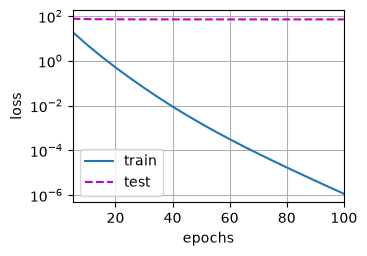

In [9]:
train(lambd=0)

w的L2范数是:  0.3437875807285309


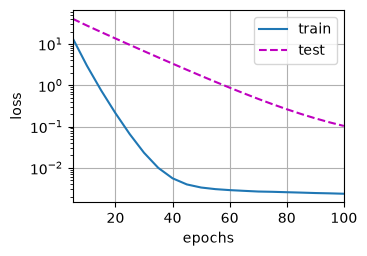

In [10]:
train(lambd=3)

w的L2范数是:  0.043518465012311935


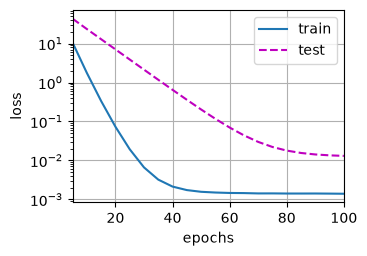

In [11]:
train(lambd=5)

w的L2范数是:  0.020809030160307884


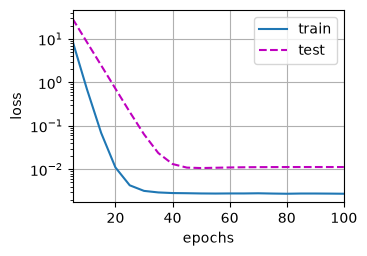

In [12]:
train(lambd=10)

w的L2范数是:  0.01386538427323103


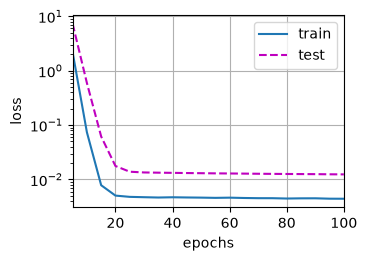

In [13]:
train(lambd=20)

In [14]:
def train_concise(wd):
    net = nn.Sequential(nn.Linear(num_inputs, 1))
    for param in net.parameters():
        param.data.normal_()
    loss = nn.MSELoss(reduction='none')
    num_epochs, lr = 100, 0.003
    trainer = torch.optim.SGD([
        {"params":net[0].weight,'weight_decay':wd},
        {"params":net[0].bias}], lr = lr)
    animator = dl_utils.Animator(xlabel='epochs', ylabel='loss', yscale='log',
                                 xlim=[5, num_epochs], legend=['train', 'test'])
    for epoch in range(num_epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.mean().backward()
            trainer.step()
        if (epoch + 1) % 5 == 0:
            animator.add(epoch + 1, (dl_utils.evaluate_loss(net, train_iter, loss),
                                     dl_utils.evaluate_loss(net, test_iter, loss)))
    print("w的L2范数是: ", net[0].weight.norm().item())


w的L2范数是:  14.91644287109375


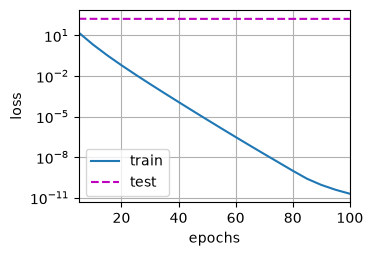

In [15]:
train_concise(0)

w的L2范数是:  0.3656601011753082


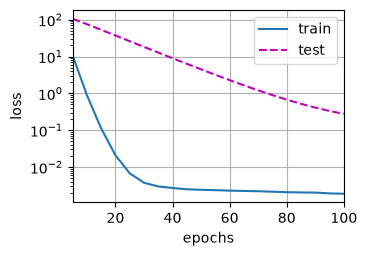

In [16]:
train_concise(3)

In [19]:
def train_wd(wd):
    net = nn.Sequential(nn.Linear(num_inputs, 1))
    for param in net.parameters():
        param.data.normal_()
    loss = nn.MSELoss(reduction='none')
    num_epochs, lr = 100, 0.003
    trainer = torch.optim.SGD([
        {"params":net[0].weight,'weight_decay':wd},
        {"params":net[0].bias}], lr = lr)
    for epoch in range(num_epochs):
        for X, y in train_iter:
            trainer.zero_grad()
            l = loss(net(X), y)
            l.mean().backward()
            trainer.step()
    return wd, (dl_utils.evaluate_loss(net, train_iter, loss), dl_utils.evaluate_loss(net, test_iter, loss))

In [25]:
def draw(wds):
    animator = dl_utils.Animator(xlabel='lambda', ylabel='loss', yscale='log', xlim=[0, 100],
                                 legend=['train', 'test'])
    for wd in wds:
        wd, loss = train_wd(wd)
        animator.add(wd, loss)

wds = range(0, 100, 5)

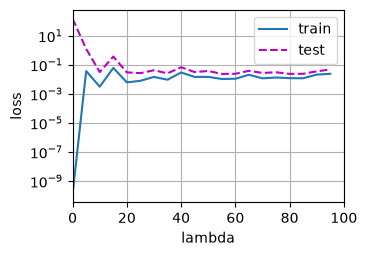

In [26]:
draw(wds)